# Noise PSD from the randoms cut: series 07221203_2025, dump F0001

Aim: redo the noise power spectrum of **Note 3** with a better-motivated set of noise traces. Note 3 averaged 14 traces from a 21-trace selection that mixed two detectors and was biased toward traces whose baseline scatter was inflated by the leading glitch samples. Here the traces are the **randoms cut**: the quiet-noise selection of Notes 2 and 2a (500-sample pretrigger window, Tight excursion band, `log10(bstd) < 0.5`) restricted to events recorded as randoms.

Everything is Detector 0 / Channel 0, as in Notes 2 and 3, and uses the shared `python/` library. Run with the `darkmatter_cli_env` kernel.

**Caveat carried over from Note 2a.** `pulse_cuts.randoms` assumes the dump's trigger-type labels are swapped (events recorded as `Physics` are taken to be randoms). This is a working assumption, not confirmed.

*Author: buddy. Draft, not yet a note.*

In [1]:
import sys
from pathlib import Path
# Find the project's python folder from wherever this notebook is, however deep.
_here = Path.cwd().resolve()
REPO = next((p for p in [_here, *_here.parents] if (p / "python" / "pulse_io.py").exists()), None)
assert REPO, "Start Jupyter from inside the NSDF-Data folder."
sys.path.insert(0, str(REPO / "python"))

import csv
import numpy as np
import matplotlib.pyplot as plt
from nsdf_dark_matter.idx import load_all_data

import pulse_io as pio
import pulse_quantities as pq
import pulse_operations as po
import pulse_cuts as pc
from pulse_config import PulseConfig

import check_environment
check_environment.check()

Environment OK: Python 3.12.15, and the 8 packages in requirements.txt match.


[]

## 1. Load the dump and make the cut

`config_500` measures the baseline over the first 500 samples (so `dev`, the largest excursion, is measured only after sample 500), and skips the first 10 samples, which can carry an electronics glitch.

In [2]:
DUMP = "07221203_2025_F0001"
DETECTOR, CHANNEL = 0, 0
config_500 = PulseConfig(pretrigger_samples=500, glitch_samples=10, sample_period_s=1.6e-6)

cdms = load_all_data(str(Path.home() / "idx" / DUMP))
ids, pulses = pio.load_channel_batch(cdms, pio.filter_by_detector(cdms.get_detector_ids(), DETECTOR), CHANNEL)
event = np.array([int(pio.event_id(i)) for i in ids])
trig = pio.trigger_types(cdms, ids)          # trigger label from the dump's .csv, one per trace
print(f"{len(ids)} traces, events {event.min()}-{event.max()}; trigger labels:",
      {t: int((trig == t).sum()) for t in np.unique(trig)})

1517 traces, events 10000-11569; trigger labels: {np.str_('Physics'): 1008, np.str_('Unknown'): 509}


## 2. The randoms cut

The cut is defined in this one cell, so it is easy to change. It is the Note 2a selection: Tight band (`log10(ratio)` in [0.5, 0.7)) plus `log10(bstd) < 0.5`, then `randoms`. Note 2a reports 179 traces before the trigger-label step and 141 after it for this detector and channel.

In [3]:
bstd_500 = pq.bstd(pulses, config_500)
quiet_noise = pc.excursion_band(pulses, config_500) & (np.log10(bstd_500) < 0.5)
sel_randoms = quiet_noise & pc.randoms(trig)          # <- the randoms cut
sel_real = quiet_noise & pc.real_triggers(trig)

print(f"quiet-noise selection:           {quiet_noise.sum()} traces   (Note 2a: 179)")
print(f"  of which randoms (the cut):    {sel_randoms.sum()} traces   (Note 2a: 141)")
print(f"  of which real triggers:        {sel_real.sum()} traces")
print(f"randoms cut: events {event[sel_randoms].min()}-{event[sel_randoms].max()}, "
      f"bstd median {np.median(bstd_500[sel_randoms]):.2f} counts")

quiet-noise selection:           179 traces   (Note 2a: 179)
  of which randoms (the cut):    141 traces   (Note 2a: 141)
  of which real triggers:        38 traces
randoms cut: events 10010-11433, bstd median 1.51 counts


C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\2340683059.py:3: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  sel_randoms = quiet_noise & pc.randoms(trig)          # <- the randoms cut
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\2340683059.py:4: UserWarning: real_triggers is marked under_development: the other half of the randoms assumption: events recorded as 'Unknown' are taken to be real (pulse-triggered) events. Not confirmed; see `randoms`
  sel_real = quiet_noise & pc.real_triggers(trig)


## 3. Look at the traces

Thirty of the selected traces, baseline-subtracted, zoomed on the noise. A good noise set looks like featureless scatter around zero.

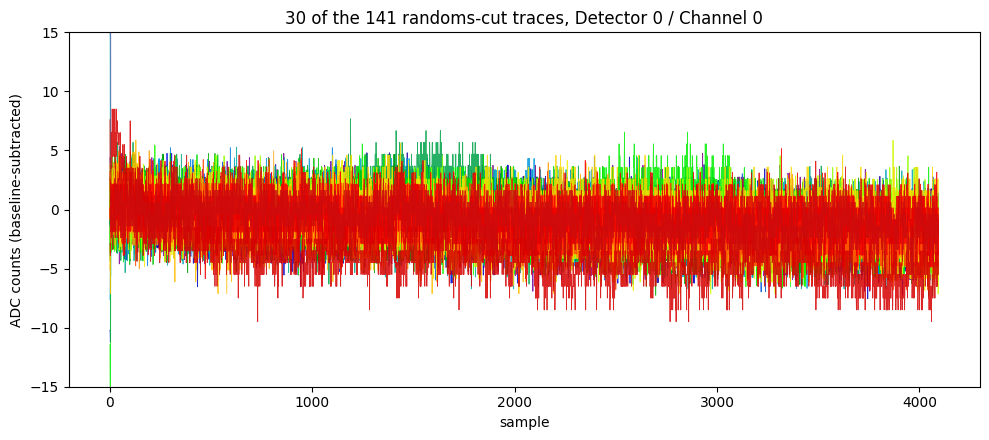

In [4]:
bl = pq.bline(pulses, config_500)
rng = np.random.default_rng(0)
pick = rng.choice(np.flatnonzero(sel_randoms), size=min(30, sel_randoms.sum()), replace=False)
colors = plt.cm.nipy_spectral(np.linspace(0.05, 0.95, len(pick)))

fig, ax = plt.subplots(figsize=(10, 4.5))
for i, c in zip(pick, colors):
    ax.plot(pulses[i] - bl[i], linewidth=0.6, color=c, alpha=0.85)
ax.set_ylim(-15, 15)    # the leading glitch (up to hundreds of counts) runs off the plot
ax.set_xlabel("sample")
ax.set_ylabel("ADC counts (baseline-subtracted)")
ax.set_title(f"{len(pick)} of the {sel_randoms.sum()} randoms-cut traces, Detector {DETECTOR} / Channel {CHANNEL}")
fig.tight_layout()
plt.savefig(f'figures/chan0-traces-07221203_2025_F0001.png')
plt.show()


## 4. Power spectrum

Each trace is baseline-subtracted and its first 10 samples are trimmed before the FFT (the glitch would otherwise leak broadband power into the low bins). Two normalizations are shown:

- **raw** `|FFT|^2`, which is what Note 3 plotted, so the two can be compared directly;
- a **one-sided PSD in counts^2/Hz**, `2 * dt * |FFT|^2 / N`, with `dt` the sample period and `N` the number of samples (the DC bin is dropped). This is one common convention; check it against the thesis convention cited in Note 3 before using it for optimal filtering.

The shaded band is the 16th to 84th percentile of the individual traces at each frequency.

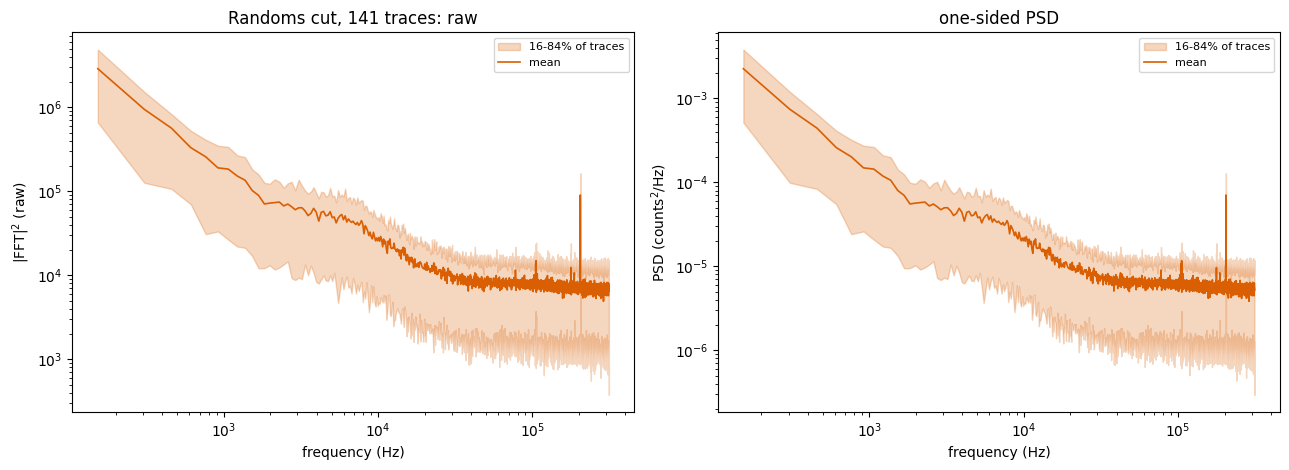

In [5]:
def processed(pulse_array):
    # baseline-subtract (500-sample window) and drop the leading glitch samples
    return po.trim_glitch(po.baseline_subtract(pulse_array, config_500), config_500)

flat = processed(pulses[sel_randoms])
n = flat.shape[-1]
freqs = pq.frequencies_hz(n, config_500)
raw = pq.power_spectrum(flat, config_500)                         # |FFT|^2, shape (traces, bins)
psd = raw * (2 * config_500.sample_period_s / n)                  # one-sided, counts^2/Hz

fig, (ax_raw, ax_psd) = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, arr, label in ((ax_raw, raw, r"$|\mathrm{FFT}|^2$ (raw)"), (ax_psd, psd, "PSD (counts$^2$/Hz)")):
    lo, mid, hi = np.percentile(arr, [16, 50, 84], axis=0)
    ax.fill_between(freqs[1:], lo[1:], hi[1:], color="#d95f02", alpha=0.25, label="16-84% of traces")
    ax.loglog(freqs[1:], arr.mean(axis=0)[1:], color="#d95f02", linewidth=1.2, label="mean")
    ax.set_xlabel("frequency (Hz)")
    ax.set_ylabel(label)
    ax.legend(fontsize=8)
ax_raw.set_title(f"Randoms cut, {flat.shape[0]} traces: raw")
ax_psd.set_title("one-sided PSD")
fig.tight_layout()
plt.show()

## 5. Compared with Note 3

Note 3 used the 21-trace `good_noise_traces.csv` selection. Restricted to Detector 0 / Channel 0 it is 12 traces (the other 2 channel-0 traces are from Detector 1). To compare the *selections* and nothing else, both sets go through exactly the same processing as above.

Note 3 selection, Detector 0 / Channel 0: 12 traces; bstd (500 samples, glitch skipped) median 1.52 counts


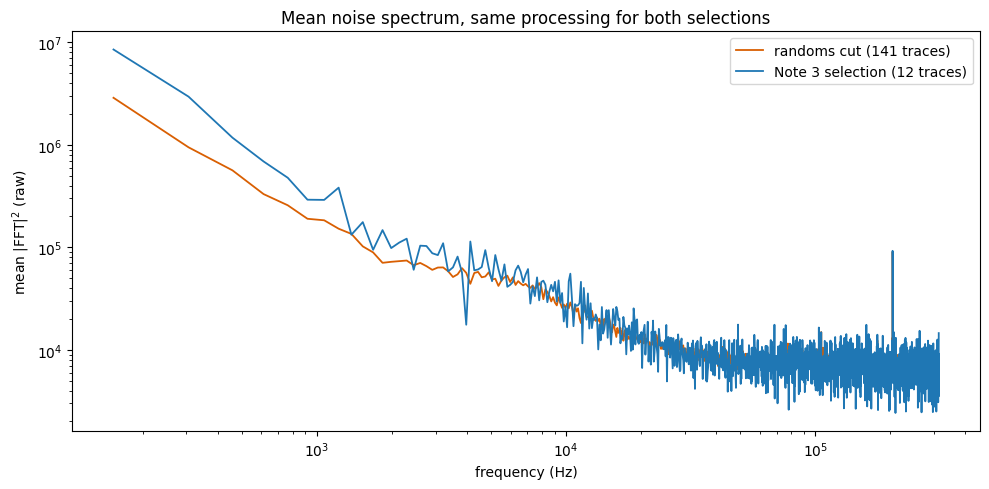

band (Hz)            randoms cut   Note 3 sel.   ratio
    1000-3000          9.35e+04      1.47e+05    0.64
    3000-10000         4.41e+04      5.24e+04    0.84
   10000-50000         1.16e+04      1.21e+04    0.96
   50000-150000        7.83e+03      7.55e+03    1.04
  250000-310000         6.8e+03      6.94e+03    0.98


In [6]:
rows = [r for r in csv.DictReader(open(REPO / "data_analysis" / "R76" / "notebooks" / "good_noise_traces.csv"))
        if int(r["channel"]) == CHANNEL and int(r["group"]) == DETECTOR]
old_ids = [f"{r['event']}_{r['group']}_Phonon_4096" for r in rows]
_, old_pulses = pio.load_channel_batch(cdms, old_ids, CHANNEL)
old_raw = pq.power_spectrum(processed(old_pulses), config_500)
print(f"Note 3 selection, Detector {DETECTOR} / Channel {CHANNEL}: {len(old_ids)} traces; "
      f"bstd (500 samples, glitch skipped) median {np.median(pq.bstd(old_pulses, config_500)):.2f} counts")

fig, ax = plt.subplots(figsize=(10, 5))
ax.loglog(freqs[1:], raw.mean(axis=0)[1:], color="#d95f02", linewidth=1.3, label=f"randoms cut ({raw.shape[0]} traces)")
ax.loglog(freqs[1:], old_raw.mean(axis=0)[1:], color="#1f77b4", linewidth=1.3, label=f"Note 3 selection ({old_raw.shape[0]} traces)")
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel(r"mean $|\mathrm{FFT}|^2$ (raw)")
ax.legend()
ax.set_title("Mean noise spectrum, same processing for both selections")
fig.tight_layout()
plt.show()

bands = [(1e3, 3e3), (3e3, 1e4), (1e4, 5e4), (5e4, 1.5e5), (2.5e5, 3.1e5)]
print(f"{'band (Hz)':<18}{'randoms cut':>14}{'Note 3 sel.':>14}{'ratio':>8}")
for lo, hi in bands:
    m = (freqs >= lo) & (freqs < hi)
    a, b = raw.mean(axis=0)[m].mean(), old_raw.mean(axis=0)[m].mean()
    print(f"{lo:>8.0f}-{hi:<8.0f}{a:>14.3g}{b:>14.3g}{a / b:>8.2f}")

## Next steps

- Describe what differs between the two spectra, and decide whether the sharp peaks of Note 7 (which Note 7 traced to two Detector 1 traces) are present here.
- Repeat for Channels 1 to 3, and for Detector 1.
- Add the other dumps of the series (F0002 to F0005) with `pio.load_channel_batch_multi`, and check that the trigger-label assumption holds there.
- When this becomes a note: it supersedes Note 3, so the Note 3 row gets the Superseded status and a link to the new note.

## 6. The other channels, with one global cut

So far everything was Channel 0 with its own cut. Here the noise spectrum is computed for every channel of Detector 0, and the same selection is used again for all 12 channels in sections 8 and 9. It is one **global cut**, the same events for every channel:

> an event is kept if it was recorded as a random (`pc.randoms`) **and** it passes the quiet-noise cut of section 2 (Tight excursion band and `log10(bstd) < 0.5`) in **every working channel**.

The quiet-noise cut is evaluated on each channel's own trace, and a channel is *working* if its own cut keeps at least 2 randoms. The other channels read a constant value, can never pass the cut, and are left out of the requirement (and out of the plots). The three boards share their events and trigger labels (the check is in the first cell below), so one list of events serves every channel. Using the global cut, instead of a separate cut for each channel, means every spectrum and every trace comes from the same events.

In [7]:
import pulse_channels as pch

def short_label(det, ch):
    """Channel name with its readout board, e.g. 'Side2pC (DCRC1)'."""
    return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"

det_ids = {det: pio.filter_by_detector(cdms.get_detector_ids(), det) for det in range(3)}

# The three boards must share their events, in the same order, so one event list serves every channel.
event_numbers = np.array([int(pio.event_id(i)) for i in det_ids[0]])
is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
for det in (1, 2):
    assert np.array_equal(event_numbers, [int(pio.event_id(i)) for i in det_ids[det]]), f"board {det} has different events"
    assert np.array_equal(is_random, pc.randoms(pio.trigger_types(cdms, det_ids[det]))), f"board {det} has different trigger labels"

# The quiet-noise cut, evaluated on each channel's own trace
quiet = {}
for det in range(3):
    for ch in range(4):
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        with np.errstate(all="ignore"):          # a constant (dead) channel has zero baseline scatter
            quiet[(det, ch)] = pc.excursion_band(p, config_500) & (np.log10(pq.bstd(p, config_500)) < 0.5)

# A channel is working if its own cut keeps at least 2 randoms; the others read a constant and can never pass
working = [key for key, q in quiet.items() if (q & is_random).sum() >= 2]

# The global cut: a random that is quiet in every working channel
global_keep = is_random.copy()
for key in working:
    global_keep &= quiet[key]

print(f"{len(event_numbers)} events on every board, {is_random.sum()} recorded as randoms\n")
print(f"{'channel':<26}{'working':<9}{'quiet & random':>15}")
for (det, ch), q in quiet.items():
    print(f"{short_label(det, ch):<26}{'yes' if (det, ch) in working else 'no':<9}{(q & is_random).sum():>15}")
print(f"\nglobal cut (random and quiet in all {len(working)} working channels): {global_keep.sum()} events")

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:11: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  is_random = pc.randoms(pio.trigger_types(cdms, det_ids[0]))
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:14: UserWarning: randoms is marked under_development: assumes the dump's trigger_type labels are swapped relative to their names: events recorded as 'Physics' are taken to be randoms (fixed-count random triggers) and 'Unknown' to be real triggers. That mapping is a working assumption from 07221203_2025_F0001 (see Note 2a), not confirmed against the DAQ configuration or the nsdf library
  assert np.array_equal(is

1517 events on every board, 1008 recorded as randoms

channel                   working   quiet & random
Side2pC (DCRC1)           yes                  141
Side2pF (DCRC1)           yes                  107
Side1pC (DCRC1)           no                     0
Side1pF (DCRC1)           yes                  109
Side1pE (DCRC3)           yes                  161
Side1pB (DCRC3)           yes                  101
Side1pD (DCRC3)           no                     0
Side2pE (DCRC3)           yes                  180
Side2pB (DCRC4)           yes                  958
Side2pA (DCRC4)           no                     0
Side1pA (DCRC4)           no                     0
Side2pD (DCRC4)           no                     0

global cut (random and quiet in all 7 working channels): 31 events


C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\Research\NSDF-Data\python\pulse_channels.py:83: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return channel_info(detector, channel).name
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed ag

Detector 0: spectra from the 31 events of the global cut

channel  name      working    own cut   used
0        Side2pC   yes            141     31
1        Side2pF   yes            107     31
2        Side1pC   no               0      0
3        Side1pF   yes            109     31


C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\1251983465.py:8: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  print(f"{ch:<9}{pch.channel_name(DETECTOR, ch):<10}{'yes' if key in working else 'no':<9}{(quiet[key] & is_random).sum():>9}{used:>7}")
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1

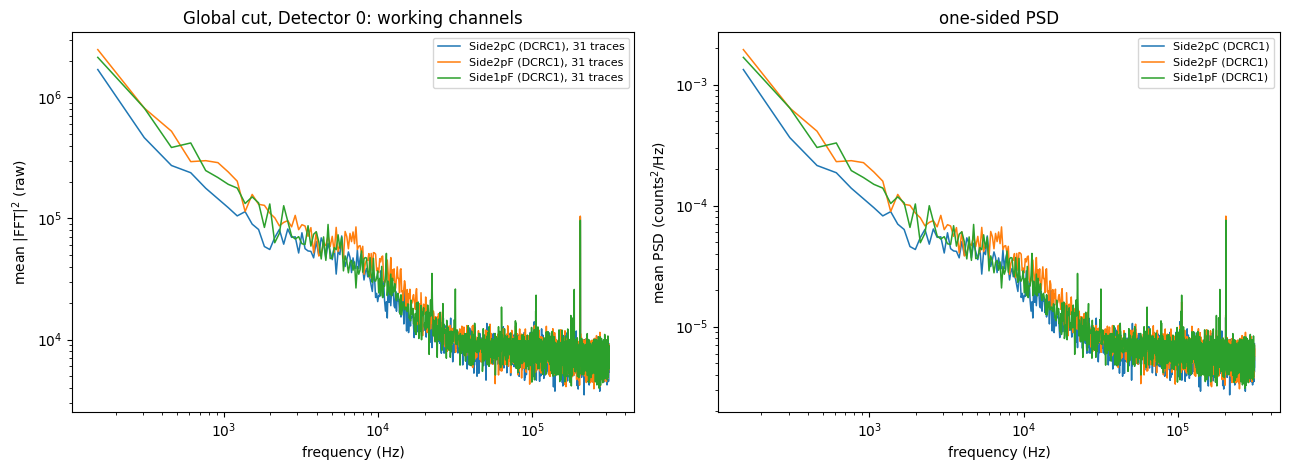

In [8]:
print(f"Detector {DETECTOR}: spectra from the {global_keep.sum()} events of the global cut\n")
print(f"{'channel':<9}{'name':<10}{'working':<9}{'own cut':>9}{'used':>7}")

by_channel = {}
for ch in range(4):
    key = (DETECTOR, ch)
    used = int(global_keep.sum()) if key in working else 0
    print(f"{ch:<9}{pch.channel_name(DETECTOR, ch):<10}{'yes' if key in working else 'no':<9}{(quiet[key] & is_random).sum():>9}{used:>7}")
    if key in working:
        _, p = pio.load_channel_batch(cdms, det_ids[DETECTOR], ch)
        by_channel[ch] = pq.power_spectrum(processed(p[global_keep]), config_500)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ch, r in by_channel.items():
    label = short_label(DETECTOR, ch)
    axes[0].loglog(freqs[1:], r.mean(axis=0)[1:], linewidth=1.1, label=f"{label}, {r.shape[0]} traces")
    axes[1].loglog(freqs[1:], (r * (2 * config_500.sample_period_s / n)).mean(axis=0)[1:], linewidth=1.1, label=label)
axes[0].set_ylabel(r"mean $|\mathrm{FFT}|^2$ (raw)")
axes[1].set_ylabel("mean PSD (counts$^2$/Hz)")
for ax in axes:
    ax.set_xlabel("frequency (Hz)")
    ax.legend(fontsize=8)
axes[0].set_title(f"Global cut, Detector {DETECTOR}: working channels")
axes[1].set_title("one-sided PSD")
fig.tight_layout()
plt.savefig(f'figures/allchan-psd-{DUMP}.png')
plt.show()

## 7. Which detector channel is which?

The dump labels its data by **detector index** (0, 1, 2) and **channel index** (0 to 3). Everything above used Detector 0 / Channel 0. To say which physical channel that is, and what the other eleven are, we need to connect those indices to the hardware.

The plan of this section:

1. the original channel table from the UMN Run 76 summary, as published;
2. our interpretation of it, and the evidence for each step;
3. a simplified table of the mapping, which the rest of the notebook uses.

The short version: the dump's three "detectors" are not three detectors. They are three 4-channel readout boards (DCRC1, DCRC3, DCRC4) of **one** two-sided detector, read out in that order.

### 7.1 The original table

The *Setup* table of the [Run 76 summary](https://villano-lab.github.io/R76Analysis/cdms/k100/run_summary/run_76.html) on the UMN wiki, as published (copied by hand; the merged Cable and DCRC cells are shown once per group):

| Tower input | Cable | DCRC (2-sided) | Label | HV output, Side 1 readout | HV output, Side 2 readout |
|---|---|---|---|---|---|
| Face5pA | Cable 2 (includes LEDs and accessories), HV CONN1 | DCRC3 | Side1pE | HV1 pA | - |
| Face5pB | | | Side1pB | HV1 pB | - |
| Face5pC | | | Side1pD | HV1 pC | - |
| Face5pD | | | Side2pE | - | HV2 pD |
| Face3pA | Cable 1, HV CONN2 | DCRC1 | Side2pC | - | HV2 pA |
| Face3pB | | | Side2pF | - | HV2 pB |
| Face3pC | | | Side1pC | HV2 pC | - |
| Face3pD | | | Side1pF | HV2 pD | - |
| Face2pA | Cable 3, HV CONN3 | DCRC4 | Side2pB | - | HV1 pA |
| Face2pB | | | Side2pA | - | HV1 pB |
| Face2pC | | | Side1pA | HV2 pB | - |
| Face2pD | | | Side2pD | - | HV1 pD |

What the table does and does not tell us: it lists 12 channels on 3 DCRC boards (4 per board), each with a `Label` (the detector channel, `Side1pA` to `Side1pF` and `Side2pA` to `Side2pF`). It does not say which board the dump calls detector 0, 1 or 2, or in what order the four channels of a board are stored. The first column (`Face5pA`, ...) is the wiki's name for the tower input each channel is wired to. It is not a face of the detector, which has only two (Side 1 and Side 2), and this notebook does not use it. The HV columns are typo-prone (for example `HV2 pB` and `HV2 pD` each appear twice), so they are not used.

### 7.2 Our interpretation

Three steps, each with its evidence and how sure we are.

**Step 1. The three "detectors" are the three DCRC boards; all 12 channels belong to one two-sided detector.** The table lists three DCRC boards of 4 channels each, and the dump has 3 detectors of 4 channels each. The `Label` column (`Side1pA` to `Side2pF`) names the real channels of the one detector. *Confident.*

**Step 2. Detector index 0, 1, 2 = DCRC1, DCRC3, DCRC4 (ascending board number).** This comes from the run configuration (the ODB) stored at the start of a raw MIDAS file. The ODB and the raw file are not on NSDF for series `07221203_2025`, so this was worked out on a different Run 76 file we have locally, `07220916_2200_F0001.mid.gz` (16 Sep 2022):

- The ODB (`/Equipment/Tower01/Settings`) has DCRC1, DCRC3 and DCRC4 enabled, and DCRC2, DCRC5 and DCRC6 disabled. This agrees with the table.
- Each event in the raw file holds three records, one per board. Every record header carries a code whose low byte is `0x09`, `0x0B`, `0x0C`, in that order, in all 286 data banks of the file.
- 9, 11, 12 are the board numbers 1, 3, 4 plus 8. We read the code as the board number plus a constant offset, which gives detector 0 = DCRC1, 1 = DCRC3, 2 = DCRC4.

*Probable, not proven:* the offset of 8 is inferred from three numbers fitting, nothing in the file states it, and the evidence is from a different series than ours. Settle it by finding the raw file or ODB for `07221203_2025` (the logger writes under `/data/chocula/k100/midasraw/` on the UMN hosts).

**Step 3. Channel index 0 to 3 within a board follows the table's row order (A, B, C, D).** An assumption: each record holds 4 channels of 4096 samples, but we have not checked their order against the ODB. *Unverified.*

**Channel names** come from the `Label` column, not the HV columns, which repeat entries and are typo-prone.

The mapping is kept in one place, the library module `python/pulse_channels.py`, tagged *under development* so that every use warns. If step 2 or 3 turns out wrong, only `DCRC_OF_DETECTOR` or `ROWS` in that file change, and every notebook follows.

### 7.3 Simplified table: dump indices to detector channels

This is the mapping used from here on (provisional, see 7.2). "Detector 0 / Channel 0" of the earlier sections is the first row. In code: `pch.channel_name(0, 0)` gives `'Side2pC'`, `pch.find_channel('Side2pC')` goes the other way.

| Detector index | Channel index | DCRC board | Detector channel (Label) |
|:-:|:-:|:-:|:-:|
| 0 | 0 | DCRC1 | Side2pC |
| 0 | 1 | DCRC1 | Side2pF |
| 0 | 2 | DCRC1 | Side1pC |
| 0 | 3 | DCRC1 | Side1pF |
| 1 | 0 | DCRC3 | Side1pE |
| 1 | 1 | DCRC3 | Side1pB |
| 1 | 2 | DCRC3 | Side1pD |
| 1 | 3 | DCRC3 | Side2pE |
| 2 | 0 | DCRC4 | Side2pB |
| 2 | 1 | DCRC4 | Side2pA |
| 2 | 2 | DCRC4 | Side1pA |
| 2 | 3 | DCRC4 | Side2pD |

Side 1 has the channels pA to pF, and so does Side 2. Each of the 12 names appears exactly once. The code cell below prints the same table from the library and checks it.

### 7.4 Where the channels are on the detector

![Channel layout of one face of the detector](figures/channelLayout.png)

*Layout of the phonon channels on one face of the detector, with the x and y axes of the detector. This is the layout of **face 1 (Side 1)**. A and B are the two outer rings, C, D and E are the three sectors of the middle region (C at the upper left, D at the lower left, E at the right, on the +x side), and F is the centre disc. Figure from the R76 thermal-neutron-peaks paper project (`figures/channelLayout.png`).*

**Face 2 (Side 2) is drawn as you would see it after flipping the detector over.** The UMN wiki's source-position figure (`r76_r75_source_positions.png`, which shows both faces side by side) draws Side 2 with the same sector layout as Side 1, E on the right, C at the upper left and D at the lower left, but with its x axis pointing to the *left*. That is the view of face 2 itself, and it is the view used for Side 2 in section 7.5. In the x-y frame of face 1 (the frame of the figure above, +x to the right), the same E sector of face 2 lies on the -x side, because flipping the detector over mirrors it about the y axis. A and B are full rings and F is the centre disc on both faces. The letter is the last character of the channel name, so `A` is `Side1pA` on face 1 and `Side2pA` on face 2.

For example, our Detector 0 / Channel 0 is `Side2pC`: the C sector of face 2, at the upper left of the face-2 drawing of 7.5 (and the upper right in the x-y frame of face 1). Channel 2 of the same board is `Side1pC`, the C sector of face 1, at the upper left, and channel 3 is `Side1pF`, the centre disc of face 1.

In [9]:
# The mapping lives in the library (python/pulse_channels.py), so every notebook uses the same one.
# Step 2 of 7.2 (detector index -> DCRC board) is pch.DCRC_OF_DETECTOR, step 3 (channel order in a board)
# is the row order of pch.ROWS.
import pulse_channels as pch

print(f"{'det':<5}{'chan':<6}{'DCRC':<8}{'detector channel':<18}")
for c in pch.all_channels():
    print(f"{c.detector:<5}{c.channel:<6}{c.dcrc:<8}{c.name:<18}")

assert len({c.name for c in pch.all_channels()}) == 12, "each detector channel should appear once"
print("\nExample: Detector 0 / Channel 0 is", short_label(0, 0))

det  chan  DCRC    detector channel  
0    0     DCRC1   Side2pC           
0    1     DCRC1   Side2pF           
0    2     DCRC1   Side1pC           
0    3     DCRC1   Side1pF           
1    0     DCRC3   Side1pE           
1    1     DCRC3   Side1pB           
1    2     DCRC3   Side1pD           
1    3     DCRC3   Side2pE           
2    0     DCRC4   Side2pB           
2    1     DCRC4   Side2pA           
2    2     DCRC4   Side1pA           
2    3     DCRC4   Side2pD           

Example: Detector 0 / Channel 0 is Side2pC (DCRC1)


C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\2504411141.py:7: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  for c in pch.all_channels():
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\2504411141.py:10: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  assert len({c.name for c in pch.all_channels()}) == 12, "each detector channel should appear once"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not 

### 7.5 Which channels work, on the detector layout

The two faces of the detector, each drawn as you would see it: face 1 as in 7.4, and face 2 as seen after flipping the detector over, which is how the UMN wiki figure draws it (the same sector layout, with E on the right, but with the x axis pointing to the *left*, shown by the arrow of each panel; see 7.4). Each channel is coloured by whether it is *working* (section 6: its own quiet-noise cut keeps at least 2 randoms). A working channel is coloured by side, blue for Side 1 and orange for Side 2, and a channel that reads a constant value is grey. Each region is labelled with its letter, its DCRC board (from 7.3), and the number of randoms that pass its own cut. Of the 12 channels, 7 work: `Side1pB`, `Side1pE`, `Side1pF`, `Side2pB`, `Side2pC`, `Side2pE` and `Side2pF`. The five that do not are `Side1pA`, `Side1pC`, `Side1pD`, `Side2pA` and `Side2pD`.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\3484435534.py:11: UserWarning: all_channels is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  by_name = {(c.side, c.letter): c for c in pch.all_channels()}


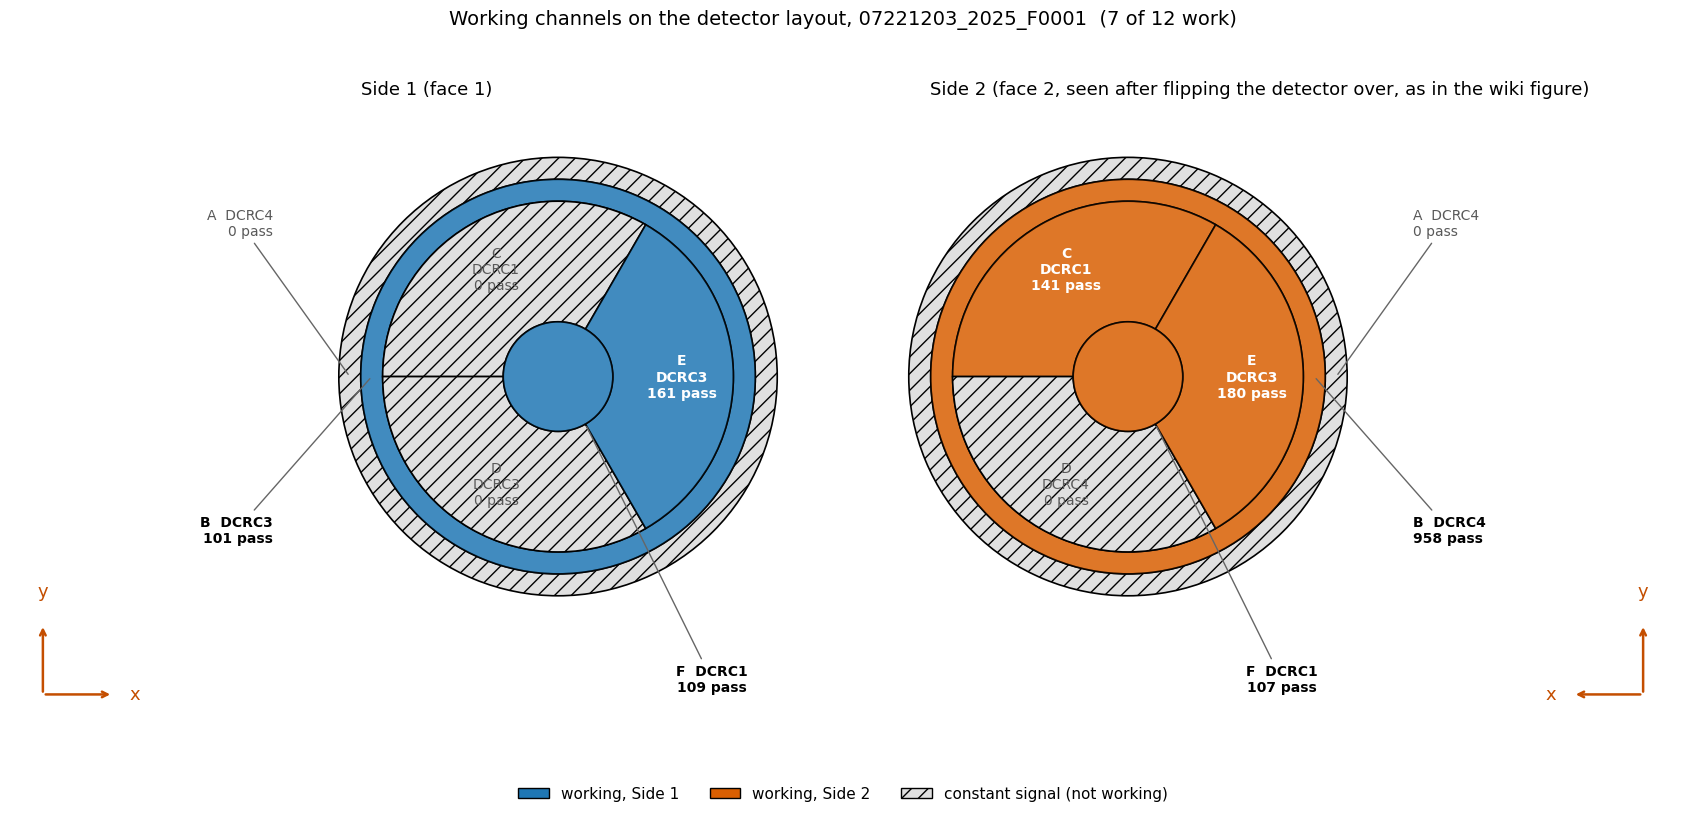

In [10]:
from matplotlib.patches import Wedge, Patch

# Geometry of a face as the wiki draws it (7.4): A = outer ring, B = second ring, C / D / E = three 120-degree
# sectors of the middle region (E on the right, C upper left, D lower left), F = centre disc. Face 2 is drawn the
# same way, as seen after flipping the detector over; only its x axis points the other way (left).
regions = {   # letter -> (inner radius, outer radius, start angle, end angle) in degrees
    "A": (0.90, 1.00, 0, 360), "B": (0.80, 0.90, 0, 360),
    "C": (0.25, 0.80, 60, 180), "D": (0.25, 0.80, 180, 300), "E": (0.25, 0.80, -60, 60),
    "F": (0.00, 0.25, 0, 360),
}
by_name = {(c.side, c.letter): c for c in pch.all_channels()}
side_colour = {1: "#1f77b4", 2: "#d95f02"}
orange_axes = "#c44e00"

fig, axes = plt.subplots(1, 2, figsize=(17, 8.2), gridspec_kw=dict(wspace=0.0))
for ax, side in zip(axes, (1, 2)):
    out = -1 if side == 1 else 1                          # the A and B labels go to the left of face 1, the right of face 2
    for letter, (r_in, r_out, a0, a1) in regions.items():
        c = by_name[(side, letter)]
        ok = (c.detector, c.channel) in working
        ax.add_patch(Wedge((0, 0), r_out, a0, a1, width=r_out - r_in, facecolor=side_colour[side] if ok else "0.88",
                           edgecolor="k", linewidth=1.2, alpha=0.85 if ok else 1.0, hatch=None if ok else "//"))
        n_pass = int((quiet[(c.detector, c.channel)] & is_random).sum())
        if letter in "CDE":
            mid = np.deg2rad((a0 + a1) / 2)
            r_mid = (r_in + r_out) / 2 + 0.04
            text = chr(10).join([letter, c.dcrc, f"{n_pass} pass"])
            ax.text(r_mid * np.cos(mid), r_mid * np.sin(mid), text, ha="center", va="center", fontsize=10,
                    fontweight="bold" if ok else "normal", color="white" if ok else "0.35")
        else:   # the small regions (A, B rings and the F disc) are labelled outside, with a line to the region
            text = chr(10).join([f"{letter}  {c.dcrc}", f"{n_pass} pass"])
            xy, xytext, ha = {"A": ((0.95 * out, 0.0), (1.3 * out, 0.7), "right" if out == -1 else "left"),
                              "B": ((0.85 * out, 0.0), (1.3 * out, -0.7), "right" if out == -1 else "left"),
                              "F": ((0.125, -0.217), (0.7, -1.38), "center")}[letter]   # F: line along the D/E boundary
            ax.annotate(text, xy=xy, xytext=xytext, fontsize=10, ha=ha, va="center",
                        color="k" if ok else "0.35", fontweight="bold" if ok else "normal",
                        arrowprops=dict(arrowstyle="-", color="0.4"))
    # the axes of the wiki figure: +x to the right on face 1, to the left on face 2, +y up on both
    gx = -2.35 if side == 1 else 2.35
    ax.annotate("", xy=(gx + 0.32 * (1 if side == 1 else -1), -1.45), xytext=(gx, -1.45),
                arrowprops=dict(arrowstyle="->", color=orange_axes, linewidth=1.8))
    ax.annotate("", xy=(gx, -1.13), xytext=(gx, -1.45), arrowprops=dict(arrowstyle="->", color=orange_axes, linewidth=1.8))
    ax.text(gx + 0.42 * (1 if side == 1 else -1), -1.45, "x", color=orange_axes, va="center", ha="center", fontsize=13)
    ax.text(gx, -1.0, "y", color=orange_axes, ha="center", fontsize=13)
    ax.set_xlim(-2.5, 1.3) if side == 1 else ax.set_xlim(-1.3, 2.5)
    ax.set_ylim(-1.6, 1.25)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Side 1 (face 1)" if side == 1 else "Side 2 (face 2, seen after flipping the detector over, as in the wiki figure)", fontsize=13)
handles = [Patch(facecolor=side_colour[1], edgecolor="k", label="working, Side 1"),
           Patch(facecolor=side_colour[2], edgecolor="k", label="working, Side 2"),
           Patch(facecolor="0.88", edgecolor="k", hatch="//", label="constant signal (not working)")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=11, frameon=False)
fig.suptitle(f"Working channels on the detector layout, {DUMP}  ({len(working)} of 12 work)", fontsize=14)
fig.subplots_adjust(left=0.01, right=0.99, top=0.9, bottom=0.07)
plt.savefig(f"figures/channel-status-{DUMP}.png", dpi=110)
plt.show()

## 8. Noise spectra of all 12 channels

The same global cut as in section 6 (a random that passes the quiet-noise cut in every working channel), now for all channels, so every tile comes from the same events. One tile per channel: rows are the three readout boards (detector index 0, 1, 2 = DCRC1, DCRC3, DCRC4) and columns are the four channels of each board, so tile `(row, column)` is `Detector row / Channel column`. Each tile shows the one-sided PSD of the globally cut traces (the mean, with the 16th to 84th percentile band of the individual traces), with the channel name from section 7 as its title and the number of traces in the corner. Side 1 channels are blue and Side 2 channels are orange. All tiles share the same axes, so levels can be compared by eye. A channel that is not working has an empty tile. The channel names are provisional (see 7.2).

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\1963426518.py:18: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  info = pch.channel_info(det, ch)


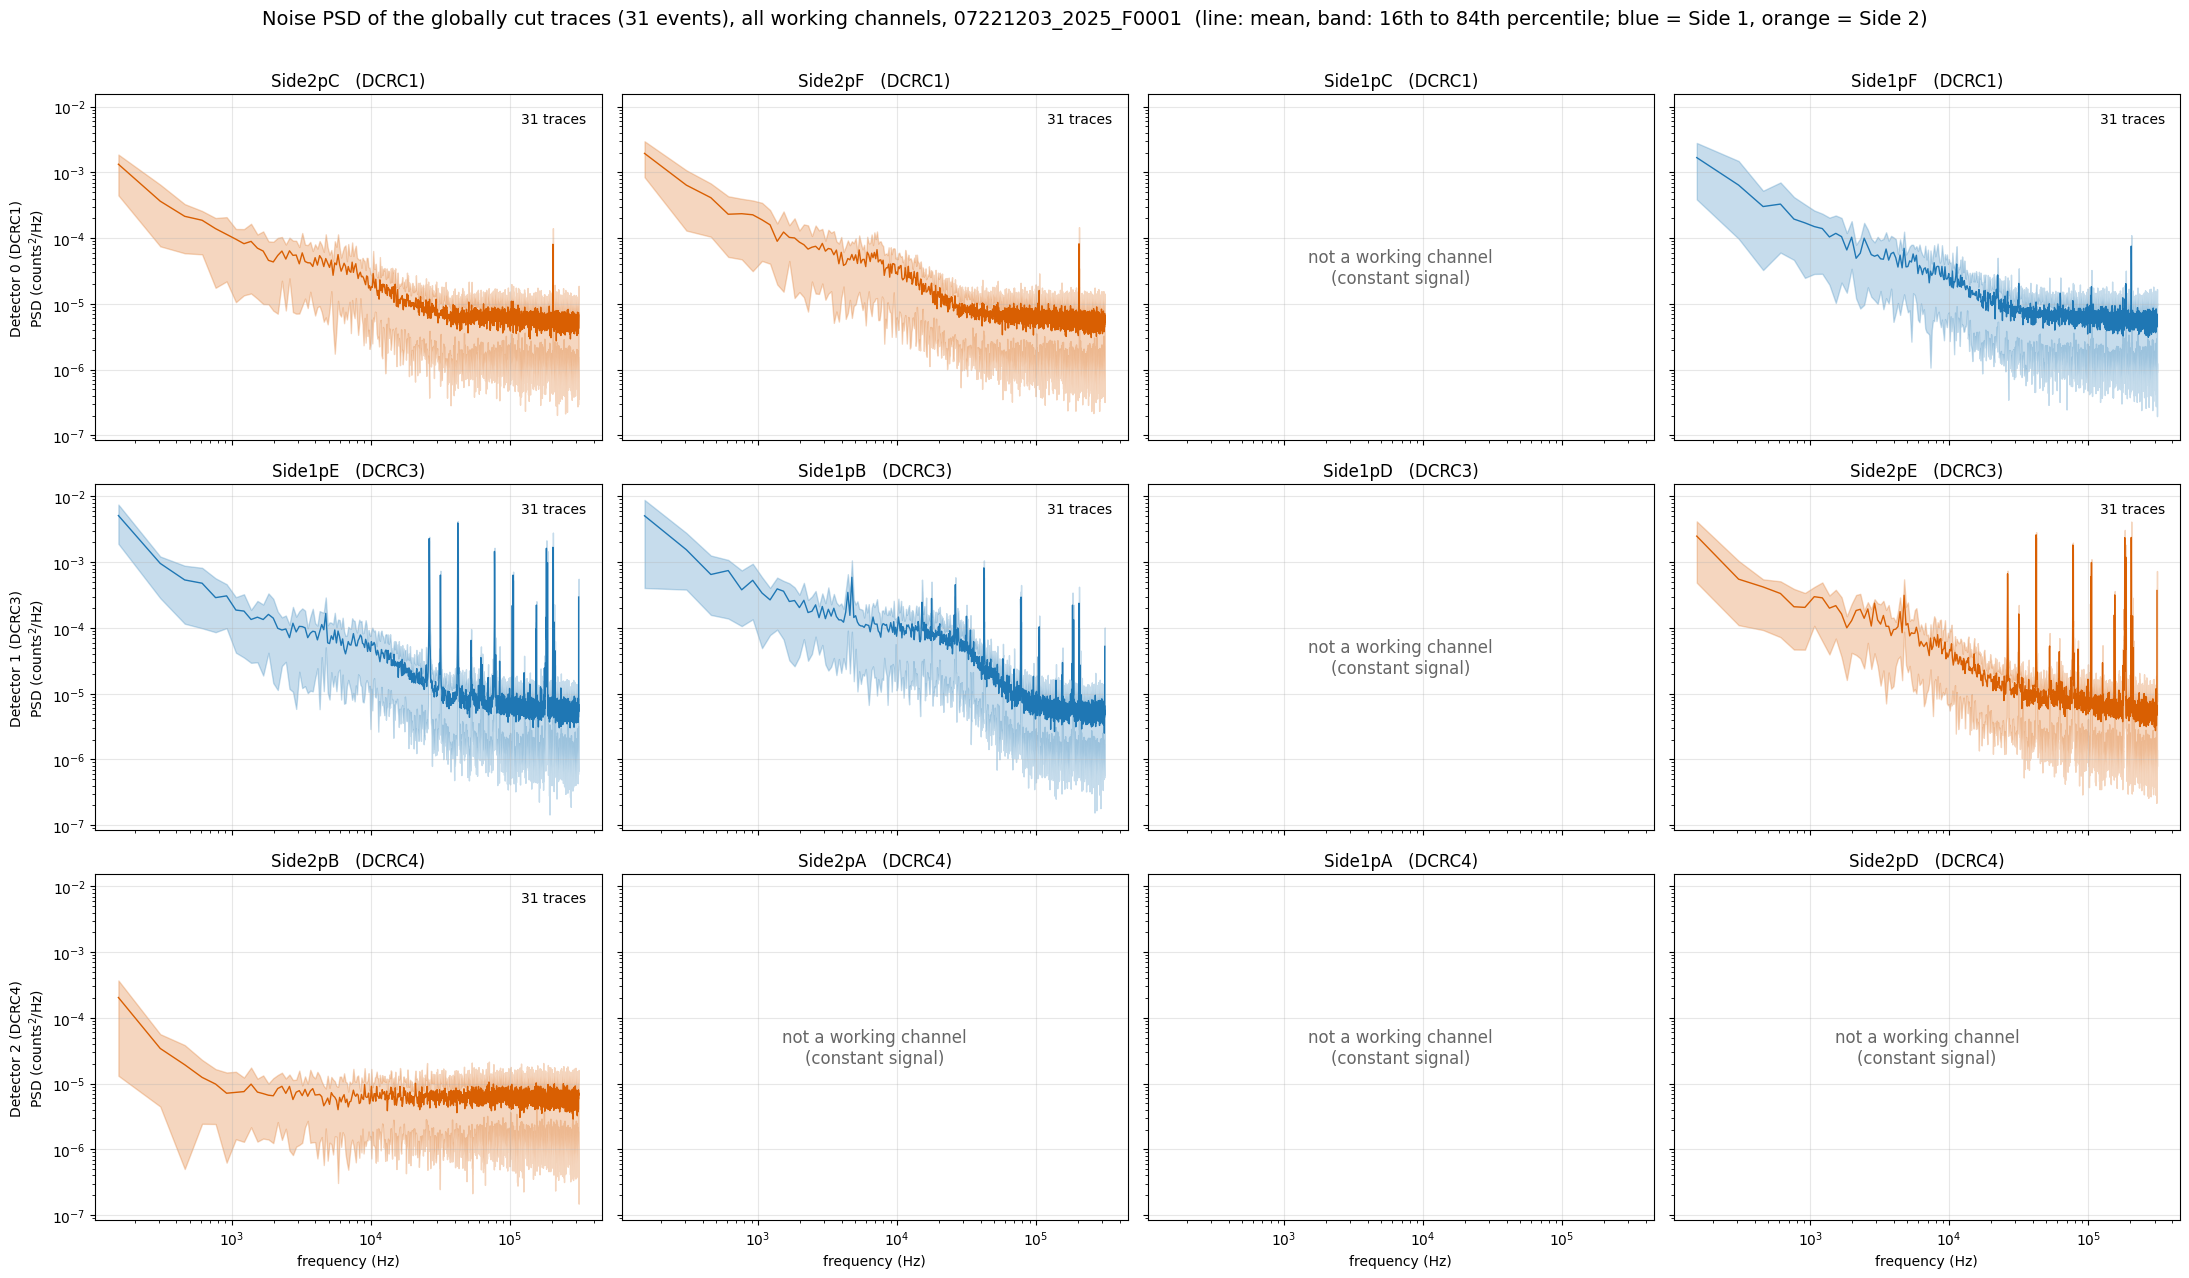

In [11]:
# One-sided PSD (counts^2/Hz) of the globally cut traces of every working channel
tiles = {}    # (detector, channel) -> (n traces, mean, 16th, 84th percentile); None for a channel that is not working
for det in range(3):
    for ch in range(4):
        if (det, ch) not in working:
            tiles[(det, ch)] = None
            continue
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        psd_ch = pq.power_spectrum(processed(p[global_keep]), config_500) * (2 * config_500.sample_period_s / n)
        lo, hi = np.percentile(psd_ch, [16, 84], axis=0)
        tiles[(det, ch)] = (int(global_keep.sum()), psd_ch.mean(axis=0), lo, hi)

side_colour = {1: "#1f77b4", 2: "#d95f02"}
fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True, sharey=True)
for det in range(3):
    for ch in range(4):
        ax = axes[det, ch]
        info = pch.channel_info(det, ch)
        ax.set_title(f"{info.name}   ({info.dcrc})", fontsize=12)
        if tiles[(det, ch)] is None:
            ax.text(0.5, 0.5, "not a working channel\n(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
        else:
            n_kept, mean, lo, hi = tiles[(det, ch)]
            colour = side_colour[info.side]
            ax.fill_between(freqs[1:], lo[1:], hi[1:], color=colour, alpha=0.25)
            ax.plot(freqs[1:], mean[1:], color=colour, linewidth=1.0)
            ax.text(0.97, 0.95, f"{n_kept} traces", transform=ax.transAxes, ha="right", va="top", fontsize=10)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.grid(True, which="major", alpha=0.3)
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({info.dcrc})\nPSD (counts$^2$/Hz)")
        if det == 2:
            ax.set_xlabel("frequency (Hz)")
fig.suptitle(f"Noise PSD of the globally cut traces ({global_keep.sum()} events), all working channels, {DUMP}  "
             "(line: mean, band: 16th to 84th percentile; blue = Side 1, orange = Side 2)", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/allchan-tiles-{DUMP}.png", dpi=110)
plt.show()

### 8.1 What the tiles show (this dump only)

- **The global cut keeps 31 of the 1008 randoms.** Seven channels are working and five are not (`Side1pC`, `Side1pD`, `Side2pA`, `Side1pA`, `Side2pD`): none of their traces ever passes the cut, because they read a constant value. Each of the six working channels on DCRC1 and DCRC3 passes the cut for only 101 to 180 randoms on its own, DCRC4's `Side2pB` for 958, and the events that fail are not the same in all of them. Any two channels share 62% to 95% of the smaller set (well above the 10 to 30 events expected by chance), but each further channel removes more, so only 31 events pass in all of them, 31% of the 101 of `Side1pB`, the strictest channel; the intersection is 31.
- **The Tight excursion band does most of the rejecting.** Only 116 to 189 of the 1008 randoms fall in the band on each of the six DCRC1 and DCRC3 channels, while the `log10(bstd) < 0.5` condition keeps 770 to 895. Replacing the band with the loose one (`excursion_band_loose`) would keep 383 events globally, but that changes the cut of Notes 2 and 2a and has not been done here.
- **With only 31 traces the spectra are noisy.** The 16th to 84th percentile bands are wide, and the lowest-frequency bins in particular scatter a lot.
- **This fits the run configuration (ODB) we read for series `07220916_2200`:** the QET bias is zero on channel 2 of both DCRC1 and DCRC3 and on all four channels of DCRC4, and DCRC4 channel 0 has its feedback disabled. Those are the channels that come out not working or flat here. This supports step 3 of 7.2 (the channel order within a board) and detector 2 = DCRC4. It does not tell DCRC1 from DCRC3, and the ODB is from a different series, so treat it as supporting evidence, not proof.
- **Spectral lines differ by board.** Both working channels of Detector 1 (DCRC3) show many narrow lines between about 25 kHz and 300 kHz. The three working channels of Detector 0 (DCRC1) show one strong line near 200 kHz and few others. DCRC4's `Side2pB` is flat, with none of the low-frequency rise of the others. Above 100 kHz the continuum of every tile except DCRC4's falls to a similar floor of about 6e-6 counts²/Hz.

## 9. A selection of the traces behind each spectrum

The same 3 × 4 tiles as section 8, but showing traces instead of spectra. The traces are the ones that went into the spectra: the events kept by the global cut of section 8 (a random that is quiet in every working channel), baseline-subtracted, with the leading glitch samples skipped.

Ten of those events are drawn at random (the draw is seeded, so the figure is reproducible), and **each event has its own colour, the same in every tile**, so one event can be followed across channels and boards. The colours are listed once, with the event numbers, at the bottom of the figure. Each tile has its own vertical scale (`y: ±N counts` in the corner), set from the typical trace scatter of that tile; traces that run off the scale are clipped. A channel that is not working has an empty tile, as in section 8.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\3692390393.py:13: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  info = pch.channel_info(det, ch)


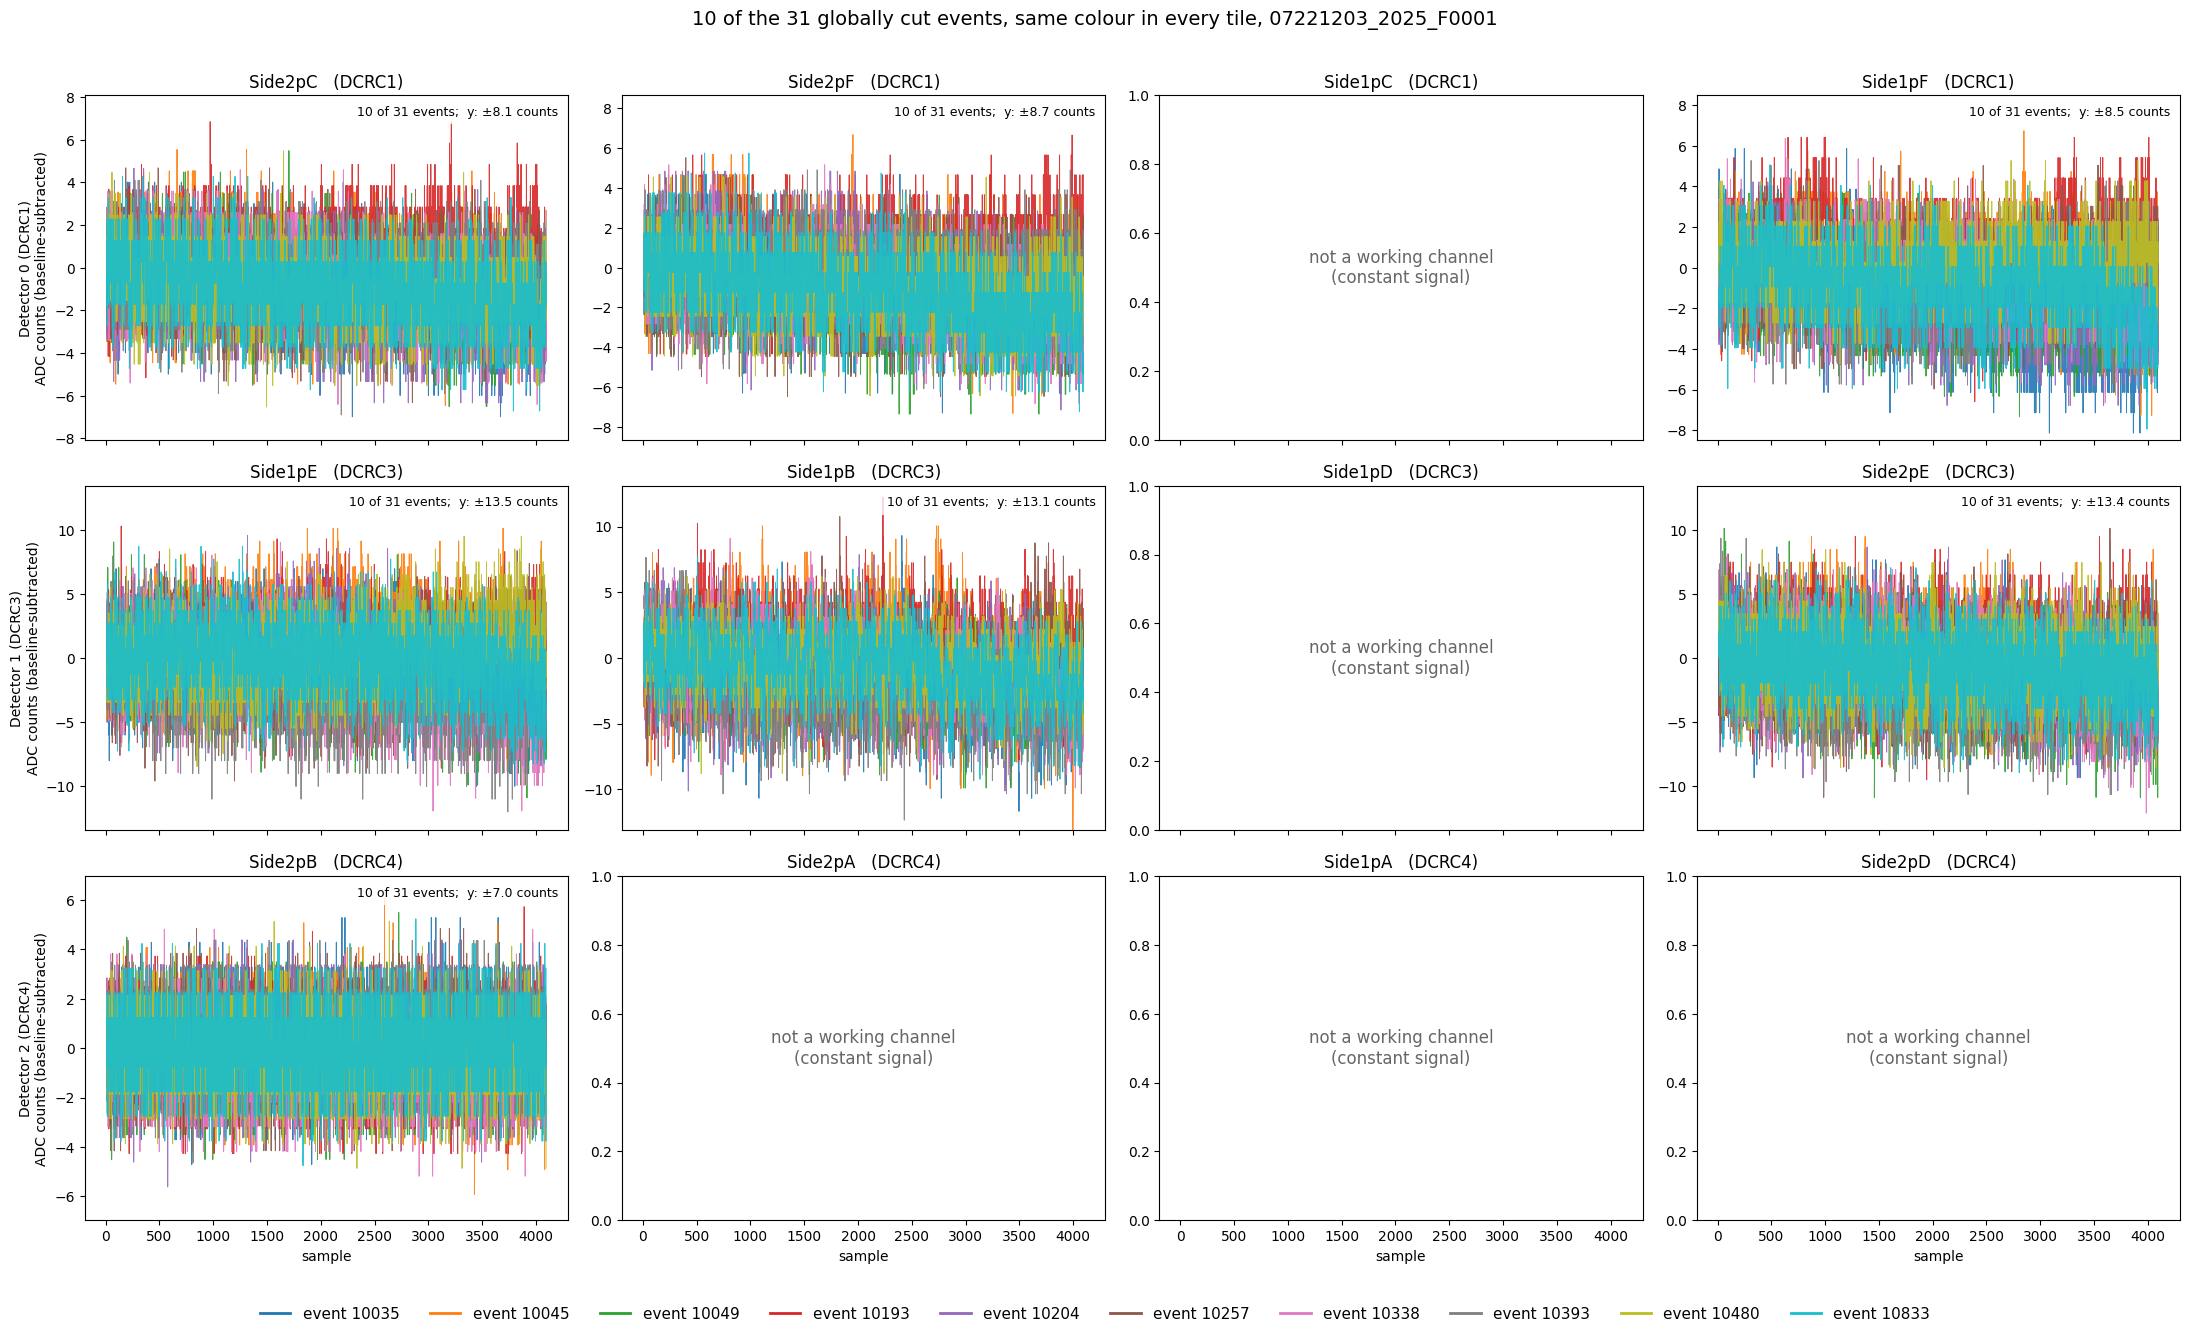

In [12]:
from matplotlib.lines import Line2D

N_SHOWN = 10
rng = np.random.default_rng(0)
glitch = config_500.glitch_samples
pick = np.sort(rng.choice(np.flatnonzero(global_keep), size=min(N_SHOWN, global_keep.sum()), replace=False))
colours = plt.cm.tab10(np.arange(len(pick)))             # one colour per event, the same in every tile
x = np.arange(glitch, 4096)

fig, axes = plt.subplots(3, 4, figsize=(22, 13.5), sharex=True)
for det in range(3):
    for ch in range(4):
        info = pch.channel_info(det, ch)
        ax = axes[det, ch]
        ax.set_title(f"{info.name}   ({info.dcrc})", fontsize=12)
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({info.dcrc})\nADC counts (baseline-subtracted)")
        if det == 2:
            ax.set_xlabel("sample")
        if (det, ch) not in working:
            ax.text(0.5, 0.5, "not a working channel\n(constant signal)", transform=ax.transAxes,
                    ha="center", va="center", color="0.4", fontsize=12)
            continue
        _, p = pio.load_channel_batch(cdms, det_ids[det], ch)
        shown = (p[pick] - pq.bline(p, config_500)[pick][:, None])[:, glitch:]   # baseline-subtracted, glitch skipped
        for trace, colour in zip(shown, colours):
            ax.plot(x, trace, color=colour, linewidth=0.7, alpha=0.9)
        lim = 5 * max(np.nanmedian(shown.std(axis=1)), 0.25)              # from the typical scatter of a trace in this tile
        ax.set_ylim(-lim, lim)
        ax.text(0.98, 0.97, f"{len(pick)} of {global_keep.sum()} events;  y: ±{lim:.1f} counts",
                transform=ax.transAxes, ha="right", va="top", fontsize=9,
                bbox=dict(facecolor="white", alpha=0.8, edgecolor="none"))
handles = [Line2D([0], [0], color=c, linewidth=2, label=f"event {event_numbers[i]}") for i, c in zip(pick, colours)]
fig.legend(handles=handles, loc="lower center", ncol=len(pick), fontsize=11, frameon=False)
fig.suptitle(f"{len(pick)} of the {global_keep.sum()} globally cut events, same colour in every tile, {DUMP}", fontsize=14)
fig.tight_layout(rect=(0, 0.04, 1, 0.97))
plt.savefig(f"figures/allchan-traces-{DUMP}.png", dpi=100)
plt.show()

### 9.1 What the traces show (this dump only)

Ten of the 31 events kept by the global cut, with one colour per event, the same in every tile. Compare the amplitudes by reading the `y: ±N` labels, since each tile has its own scale.

- **The scatter differs by board.** The tile scales are 5 times the median trace scatter, so the typical scatter is about 1.6 to 1.7 counts on the three working DCRC1 channels, 2.6 to 2.7 counts on the two working DCRC3 channels, and 1.4 counts on DCRC4's `Side2pB`.
- **The kept traces still sag slightly.** On DCRC1 and DCRC3 the cloud of traces drifts down by a count or two over the 4096 samples. This probably accounts for part of the low-frequency rise in the spectra of section 8, and it may be the tail of earlier pulses that the cut lets through. It is worth checking before the lowest frequencies are read as pure noise. DCRC4's `Side2pB` has no slope.
- **A few events look noisier than the rest in several channels at once.** For example event 10193 (red) and event 10480 (olive) sit on the high side in several tiles. That fits the failures being shared between channels (8.1), and these events may be the least quiet of the 31. This is read by eye and has not been quantified.
- **The five tiles that are empty** are the channels that are not working (see 8.1).

## 10. How much of the low-frequency rise is baseline drift?

The traces kept by the global cut still sag slightly (9.1), and a slow ramp puts power at the lowest frequencies. To see how much of the low-frequency rise of the spectra in section 8 is this drift, the PSD is computed twice from the same traces (the 31 events of the global cut, every working channel):

- **as is**: baseline-subtracted and glitch-trimmed, as in sections 4, 6 and 8;
- **detrended**: the same, after subtracting from each trace its own least-squares straight line (offset and slope).

Each tile of the first figure shows both mean spectra. The second figure shows their ratio, detrended over as is, for all working channels, and the table gives that ratio in four frequency bands together with the median drift of the traces (the total change of the fitted line across the trace, in ADC counts). A ratio near 1 means the drift does not matter in that band; a ratio well below 1 means the drift was inflating it.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\2151726079.py:24: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  info = pch.channel_info(det, ch)


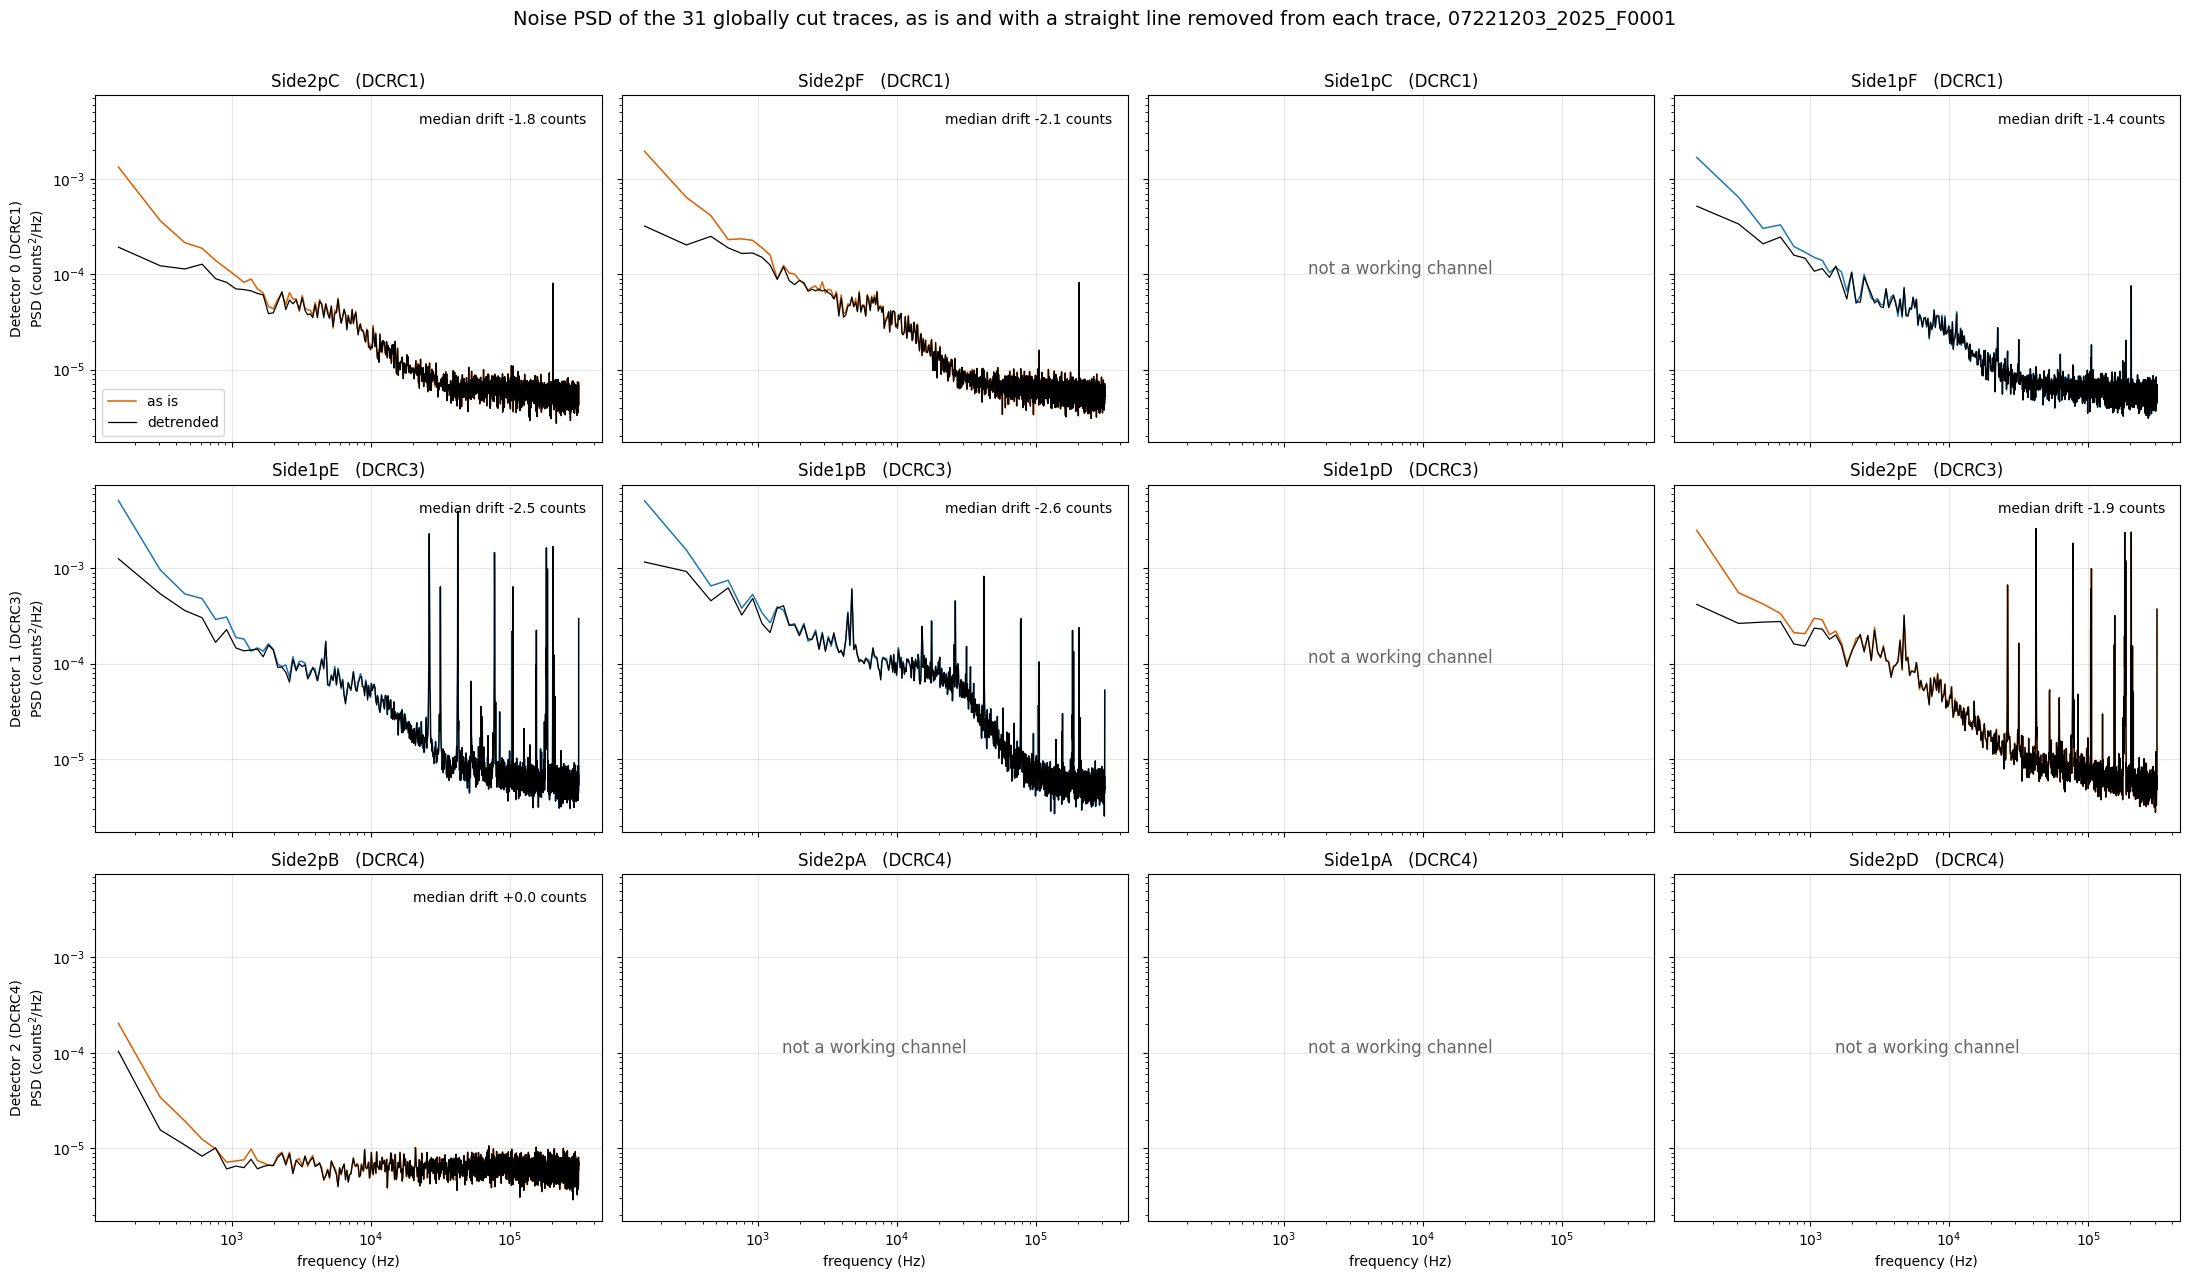

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\2151726079.py:48: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  ax.plot(freqs[1:], c["detr"][1:] / c["as_is"][1:], linewidth=1.0, label=pch.channel_name(*key))


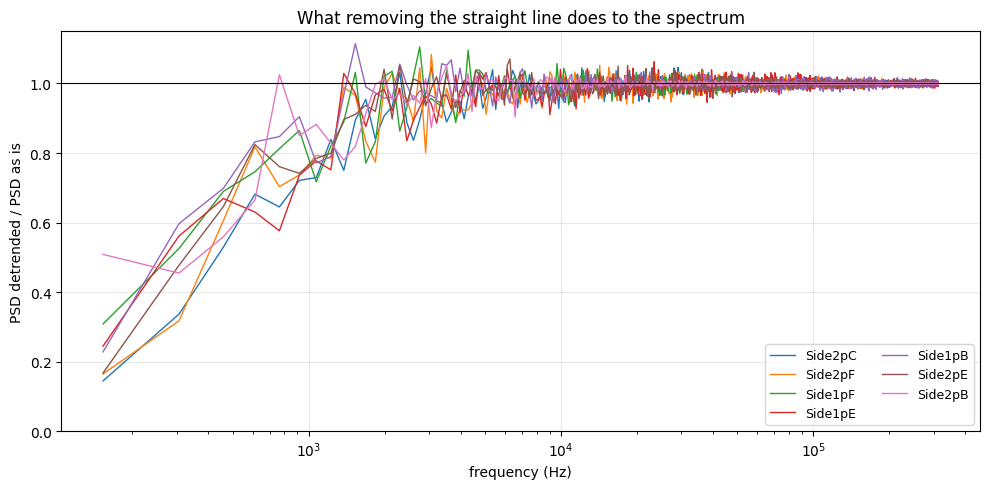

channel                     drift (counts)      153-1000        1000-10000      10000-100000    100000-312501    <- detrended / as is, by band (Hz)
Side2pC (DCRC1)               -1.8 (-2 to -1)            0.31            0.94            1.00            1.00
Side2pF (DCRC1)               -2.1 (-3 to -1)            0.35            0.94            1.00            1.00
Side1pF (DCRC1)               -1.4 (-3 to +0)            0.49            0.95            1.00            1.00
Side1pE (DCRC3)               -2.5 (-4 to -0)            0.37            0.95            1.00            1.00
Side1pB (DCRC3)               -2.6 (-5 to -0)            0.44            0.98            1.00            1.00
Side2pE (DCRC3)               -1.9 (-3 to -1)            0.37            0.96            1.00            1.00
Side2pB (DCRC4)                0.0 (-0 to +0)            0.54            0.97            1.00            1.00


C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"


In [13]:
def detrend(traces):
    """Remove a least-squares straight line (offset and slope) from each trace.
    Returns the detrended traces and the fitted slope of each trace in counts per sample."""
    t = np.arange(traces.shape[-1], dtype=float)
    design = np.stack([t, np.ones_like(t)], axis=1)                    # (samples, 2)
    coef, *_ = np.linalg.lstsq(design, traces.T, rcond=None)           # (2, traces)
    return traces - (design @ coef).T, coef[0]

norm = 2 * config_500.sample_period_s / n                              # raw |FFT|^2 -> one-sided PSD, counts^2/Hz
comparison = {}    # (detector, channel) -> mean PSD as is, mean PSD detrended, drift of every trace (counts over the trace)
for key in working:
    _, p = pio.load_channel_batch(cdms, det_ids[key[0]], key[1])
    flat_k = processed(p[global_keep])
    flat_d, slope = detrend(flat_k)
    comparison[key] = dict(as_is=(pq.power_spectrum(flat_k, config_500) * norm).mean(axis=0),
                           detr=(pq.power_spectrum(flat_d, config_500) * norm).mean(axis=0),
                           drift=slope * n)

side_colour = {1: "#1f77b4", 2: "#d95f02"}
fig, axes = plt.subplots(3, 4, figsize=(22, 13), sharex=True, sharey=True)
for det in range(3):
    for ch in range(4):
        ax = axes[det, ch]
        info = pch.channel_info(det, ch)
        ax.set_title(f"{info.name}   ({info.dcrc})", fontsize=12)
        if (det, ch) in comparison:
            c = comparison[(det, ch)]
            ax.plot(freqs[1:], c["as_is"][1:], color=side_colour[info.side], linewidth=1.1, label="as is")
            ax.plot(freqs[1:], c["detr"][1:], color="k", linewidth=0.9, label="detrended")
            ax.text(0.97, 0.95, f"median drift {np.median(c['drift']):+.1f} counts", transform=ax.transAxes,
                    ha="right", va="top", fontsize=10)
            if (det, ch) == working[0]:
                ax.legend(loc="lower left", fontsize=10)
        else:
            ax.text(0.5, 0.5, "not a working channel", transform=ax.transAxes, ha="center", va="center", color="0.4", fontsize=12)
        ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(True, which="major", alpha=0.3)
        if ch == 0:
            ax.set_ylabel(f"Detector {det} ({info.dcrc})" + chr(10) + "PSD (counts$^2$/Hz)")
        if det == 2:
            ax.set_xlabel("frequency (Hz)")
fig.suptitle(f"Noise PSD of the {global_keep.sum()} globally cut traces, as is and with a straight line removed from each trace, {DUMP}", fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.savefig(f"figures/allchan-detrended-tiles-{DUMP}.png", dpi=110)
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
for key, c in comparison.items():
    ax.plot(freqs[1:], c["detr"][1:] / c["as_is"][1:], linewidth=1.0, label=pch.channel_name(*key))
ax.axhline(1, color="k", linewidth=0.8)
ax.set_xscale("log"); ax.set_xlabel("frequency (Hz)"); ax.set_ylabel("PSD detrended / PSD as is")
ax.set_ylim(0, 1.15); ax.legend(ncol=2, fontsize=9); ax.grid(True, which="major", alpha=0.3)
ax.set_title("What removing the straight line does to the spectrum")
fig.tight_layout()
plt.savefig(f"figures/allchan-detrended-ratio-{DUMP}.png", dpi=110)
plt.show()

bands = [(freqs[1], 1e3), (1e3, 1e4), (1e4, 1e5), (1e5, freqs[-1] + 1)]
print(f"{'channel':<26}{'drift (counts)':>16}" + "".join(f"{lo:>9.0f}-{hi:<7.0f}" for lo, hi in bands) + "   <- detrended / as is, by band (Hz)")
for key, c in comparison.items():
    ratios = [c["detr"][(freqs >= lo) & (freqs < hi)].mean() / c["as_is"][(freqs >= lo) & (freqs < hi)].mean() for lo, hi in bands]
    d = c["drift"]
    print(f"{short_label(*key):<26}{np.median(d):>8.1f} ({np.percentile(d, 16):+.0f} to {np.percentile(d, 84):+.0f})".ljust(42)
          + "".join(f"{r:>16.2f}" for r in ratios))

### 10.1 What detrending changes (this dump only)

- **It only matters below about 1 kHz.** From about 1.5 kHz up, the detrended and as-is spectra lie on top of each other: the ratio is 0.94 to 0.98 averaged over 1 to 10 kHz and 1.00 above 10 kHz, on every working channel. The narrow lines (the one near 200 kHz on DCRC1, the many lines on DCRC3) do not change at all.
- **Below 1 kHz it removes a lot.** Averaged over 153 to 1000 Hz the detrended power is 0.31 to 0.49 of the as-is power on the six DCRC1 and DCRC3 channels, and in the lowest frequency bin (153 Hz) only about 0.15 to 0.3 of it.
- **So the drift explains the steepest part of the rise, in the lowest few bins, not the rise over 1 to 100 kHz.** Between 1 kHz and 100 kHz the spectra fall from about 1e-4 to about 1e-5 counts²/Hz, and they do so just the same after detrending. That part of the shape is not baseline drift.
- **Part of the sub-kHz change is not drift at all.** DCRC4's `Side2pB` has no drift (median change 0.0 counts over the trace), yet its 153 to 1000 Hz band also drops, to 0.54, because a straight line fitted to any noise trace takes away the lowest-frequency part of that noise. The drift-specific part for DCRC1 and DCRC3 is the difference between their 0.31 to 0.49 and this 0.54, which is modest.
- **The drift itself is small:** the median change of the fitted line across the 4096 samples is between -1.4 and -2.6 counts on the six DCRC1 and DCRC3 channels, against a trace scatter of about 1.6 to 2.7 counts (9.1).

For the spectra of this notebook, detrending is irrelevant above 1 kHz. Below 1 kHz, quote the lowest bins with care: they depend on whether a line is removed, and with only 31 traces they are noisy anyway.

## 11. Noise spectra of the 31 events, by side

The same spectra as section 8 (the 31 events of the global cut, one-sided PSD, mean of the traces), but with the channels of each side drawn **together** to compare them: Side 1 on the left and Side 2 on the right, one colour per channel. Only the 7 working channels appear; the other 5 read a constant value.

C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4222027605.py:3: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  keys = [(d, c) for d in range(3) for c in range(4) if (d, c) in working and pch.channel_info(d, c).side == side]
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_name is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferred, and the channel order within a board is assumed; not yet confirmed against the run's ODB
  return f"{pch.channel_name(det, ch)} ({pch.channel_info(det, ch).dcrc})"
C:\Users\villanoa\AppData\Local\Temp\ipykernel_25868\4067169979.py:5: UserWarning: channel_info is marked under_development: the dump's detector index -> DCRC board order (0,1,2 = DCRC1,DCRC3,DCRC4) is inferr

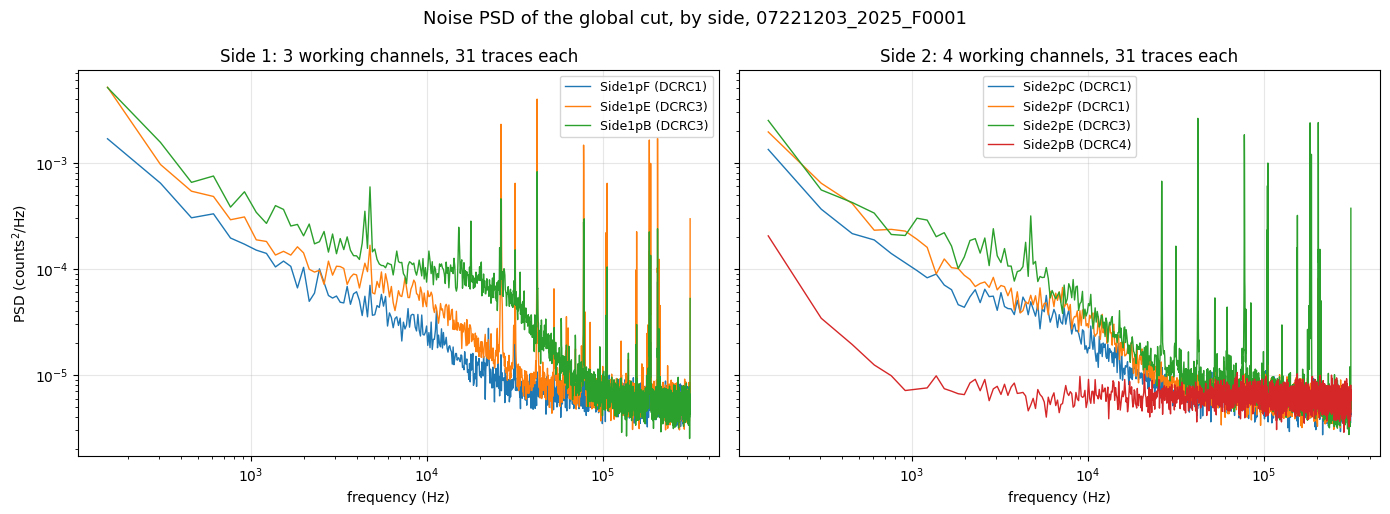

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharex=True, sharey=True)
for ax, side in zip(axes, (1, 2)):
    keys = [(d, c) for d in range(3) for c in range(4) if (d, c) in working and pch.channel_info(d, c).side == side]
    for colour_index, (d, c) in enumerate(keys):
        n_kept, mean, lo, hi = tiles[(d, c)]
        ax.loglog(freqs[1:], mean[1:], linewidth=1.0, color=f"C{colour_index}", label=f"{short_label(d, c)}")
    ax.set_title(f"Side {side}: {len(keys)} working channels, {int(global_keep.sum())} traces each")
    ax.set_xlabel("frequency (Hz)")
    ax.grid(True, which="major", alpha=0.3)
    ax.legend(fontsize=9)
axes[0].set_ylabel("PSD (counts$^2$/Hz)")
fig.suptitle(f"Noise PSD of the global cut, by side, {DUMP}", fontsize=13)
fig.tight_layout()
plt.savefig(f"figures/allchan-psd-by-side-{DUMP}.png", dpi=110)
plt.show()